In [1]:
# EXPLORATORY DATA ANALYSIS

# Data Overview
# 35,680 articles, 29 raw features + target `shares`.
# `shares` is heavily right-skewed, typical of viral content metrics
# Missing values: `num_videos` (~47%, imputed as 0 — no video embedded), `data_channel` (~15%, imputed as `"unknown"` category), and a handful of link/image/self-reference columns (~2%, median-imputed).
# No duplicates.

import numpy as np
import pandas as pd  
import seaborn as sns
import matplotlib.pyplot as plt  

# Load the dataset  
df = pd.read_csv('./data/mini_project_1_data.csv')

# Inspect dataset
print("\nShape of the dataset:" )
print(df.shape)
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows of the dataset:")
print(df.head())
print("\nStatistical Summary:")
print(df.describe())

# Duplicates
print("\nNumber of duplicate rows:")   
print(df.duplicated().sum())

# Missing Values 
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTarget summary stats:")
print(df['shares'].describe())

# Drop identifier / non-predictive columns
df = df.drop(columns=["ID", "URL"])


Shape of the dataset:
(35680, 30)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         35680 non-null  int64  
 1   URL                        35680 non-null  str    
 2   timedelta                  35680 non-null  float64
 3   weekday                    35680 non-null  str    
 4   shares                     35680 non-null  int64  
 5   n_tokens_title             35680 non-null  float64
 6   n_tokens_content           35680 non-null  float64
 7   n_unique_tokens            35680 non-null  float64
 8   n_non_stop_words           35680 non-null  float64
 9   n_non_stop_unique_tokens   35680 non-null  float64
 10  num_hrefs                  34959 non-null  float64
 11  num_self_hrefs             34959 non-null  float64
 12  num_imgs                   34261 non-null  float64
 13  num_vid

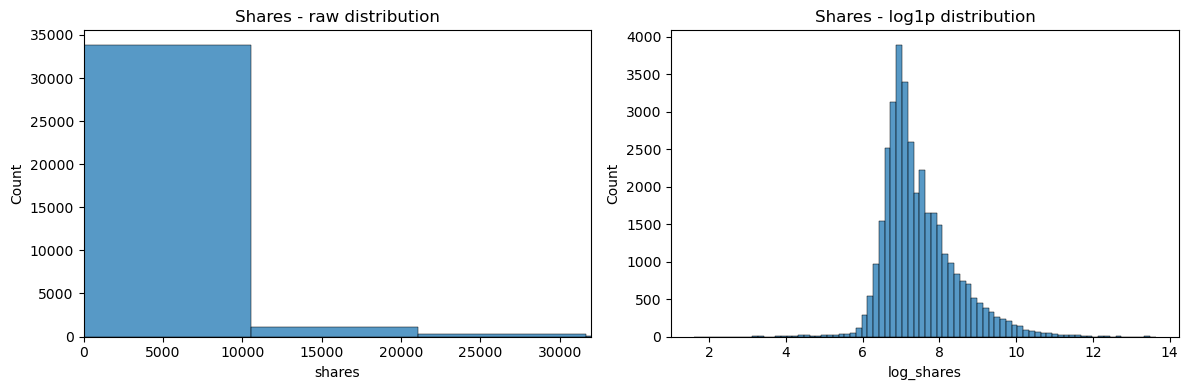


Shares skewness (raw)      : 34.41
Shares skewness (log1p)    : 1.04


In [2]:
# Target distribution

# Target variable `shares` is heavily right-skewed (skew ≈ 34), typical of viral content metrics
# most articles get modest engagement, a few go viral. 
# # A log transformation 'log_shares' is applied to stabilize variance and improve model performance.
# metrics reported on both scales.

# Log Transformation of Target Variable
df['log_shares'] = np.log1p(df['shares'])


# Histogram subplot for shares and log_shares
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram for shares
sns.histplot(df["shares"], bins=80, ax=axes[0])
axes[0].set_title("Shares - raw distribution")
axes[0].set_xlim(0, df["shares"].quantile(0.99))

# Histogram for log_shares
sns.histplot(df["log_shares"], bins=80, ax=axes[1])
axes[1].set_title("Shares - log1p distribution")
plt.tight_layout()
plt.savefig("./output/eda_target_distribution.png", dpi=110)
plt.show()

print(f"\nShares skewness (raw)      : {df['shares'].skew():.2f}")
print(f"Shares skewness (log1p)    : {df['log_shares'].skew():.2f}")

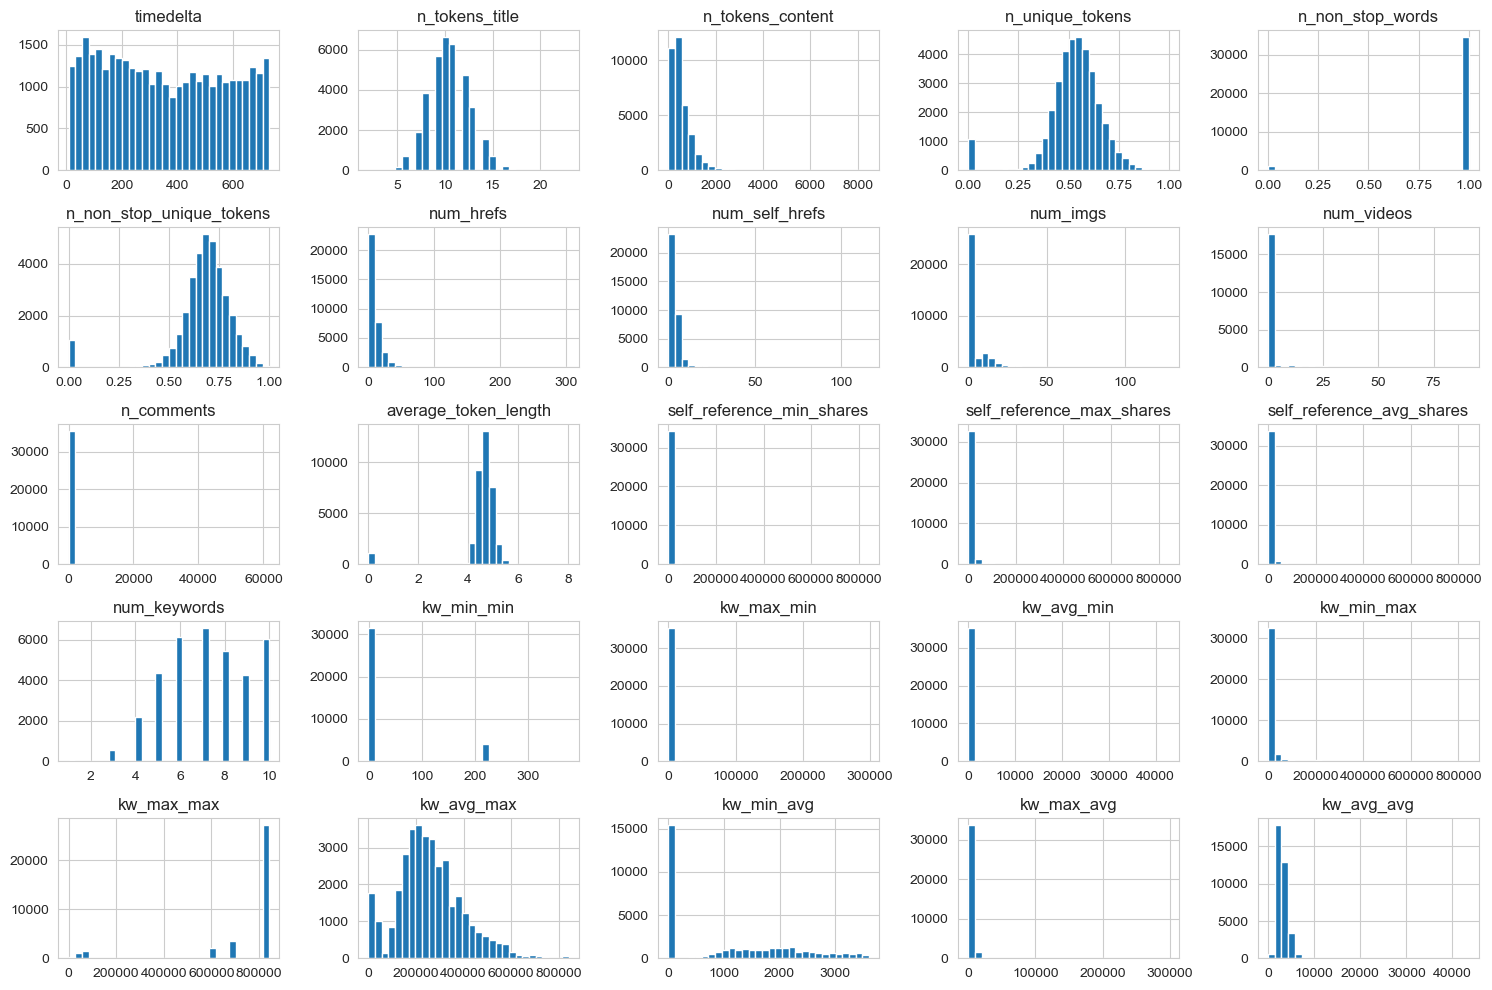

In [3]:
# Numerical Columns

# Observations
# 27 numerical columns, including content features (text stats) and engagement features (comments, references)
# Skewed distributions are observed in many numerical features, which may require transformations or scaling for modeling.


# Histograms for Numeric columns
sns.set_style("whitegrid")

# Select numeric columns
num_cols = df.select_dtypes(include=["number"]).columns

# Remove target column
num_cols = num_cols.drop(["ID", "shares", "log_shares"], errors="ignore")

df[num_cols].hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()



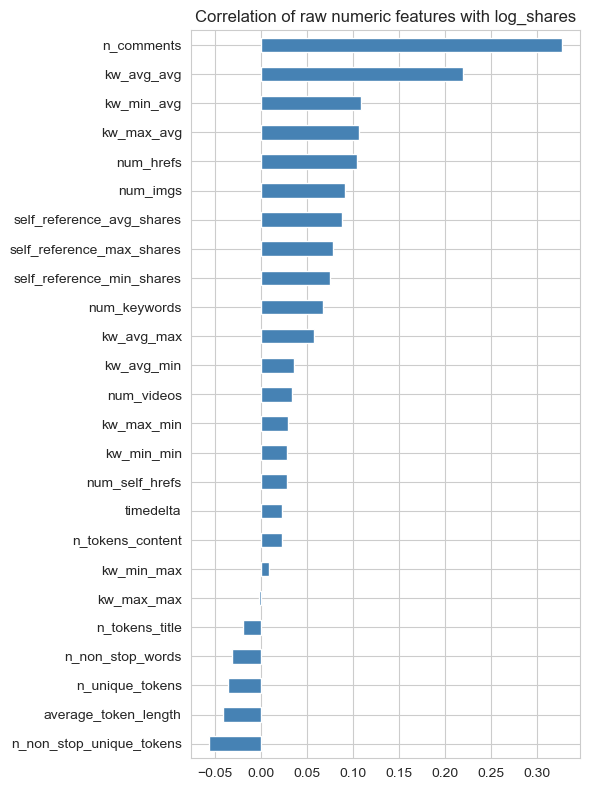

In [4]:
# Correlation

# Correlation analysis helps identify relationships between features and the target variable.
# n_comments has strong positive correlation with shares, indicating that articles with more comments tend to have higher shares.
# however, n_comments is not available at the time of publishing of the article, so it cannot be used as a predictive feature.
# Remaining features show weak/moderate correlation with log_shares, suggesting limited linear relationships.


num_cols = df.select_dtypes(include=[np.number]).columns.drop(["shares"])
corr_with_target = (
    df[num_cols].assign(log_shares=df['log_shares'])
    .corr()["log_shares"].drop("log_shares").sort_values()
)
plt.figure(figsize=(6, 8))
corr_with_target.plot(kind="barh", color="steelblue")
plt.title("Correlation of raw numeric features with log_shares")
plt.tight_layout()
plt.savefig("./output/eda_correlations.png", dpi=110)
plt.show()

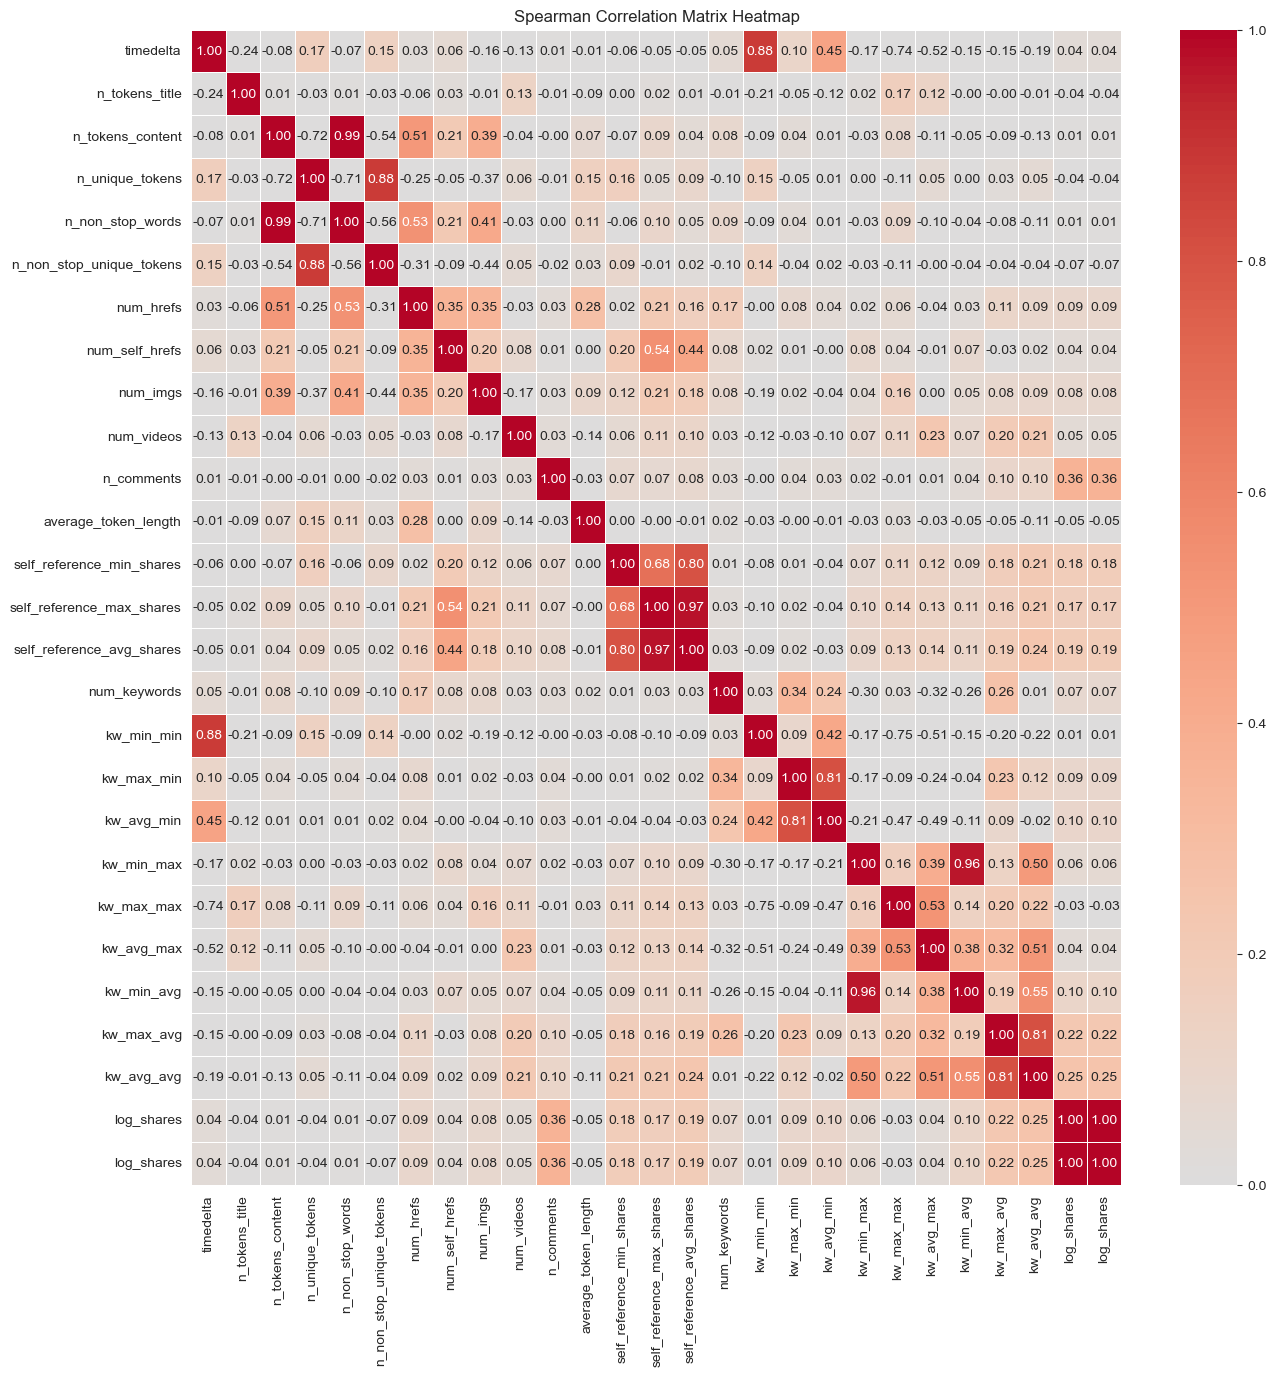

In [5]:
# Spearman Rank Correlation
# used to measure the strength and direction of the monotonic relationship between two variables. 
# It is a non-parametric measure, meaning it does not assume a specific distribution for the data. 
# Spearman correlation is particularly useful when the relationship between variables is not linear or when the data contains outliers. 
# It is based on the ranks of the data rather than the raw values, making it more robust to non-normal distributions and extreme values.


# Select relevant columns for correlation analysis
spearman_vars = df[num_cols.tolist() + ['log_shares']]

# Compute the Spearman correlation matrix
spearman_corr = spearman_vars.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(15, 15))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

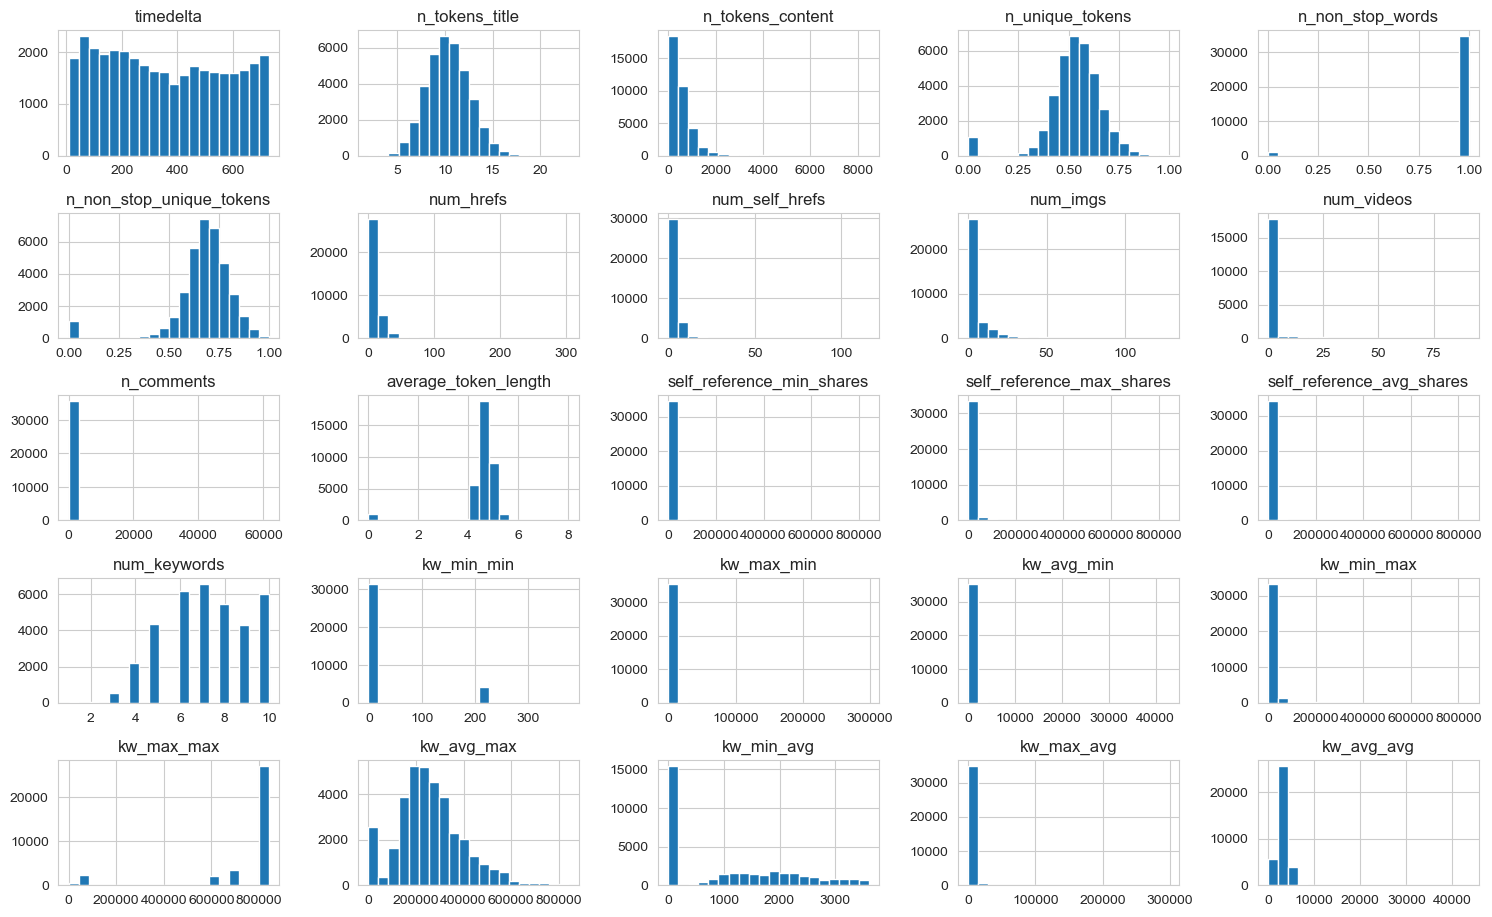

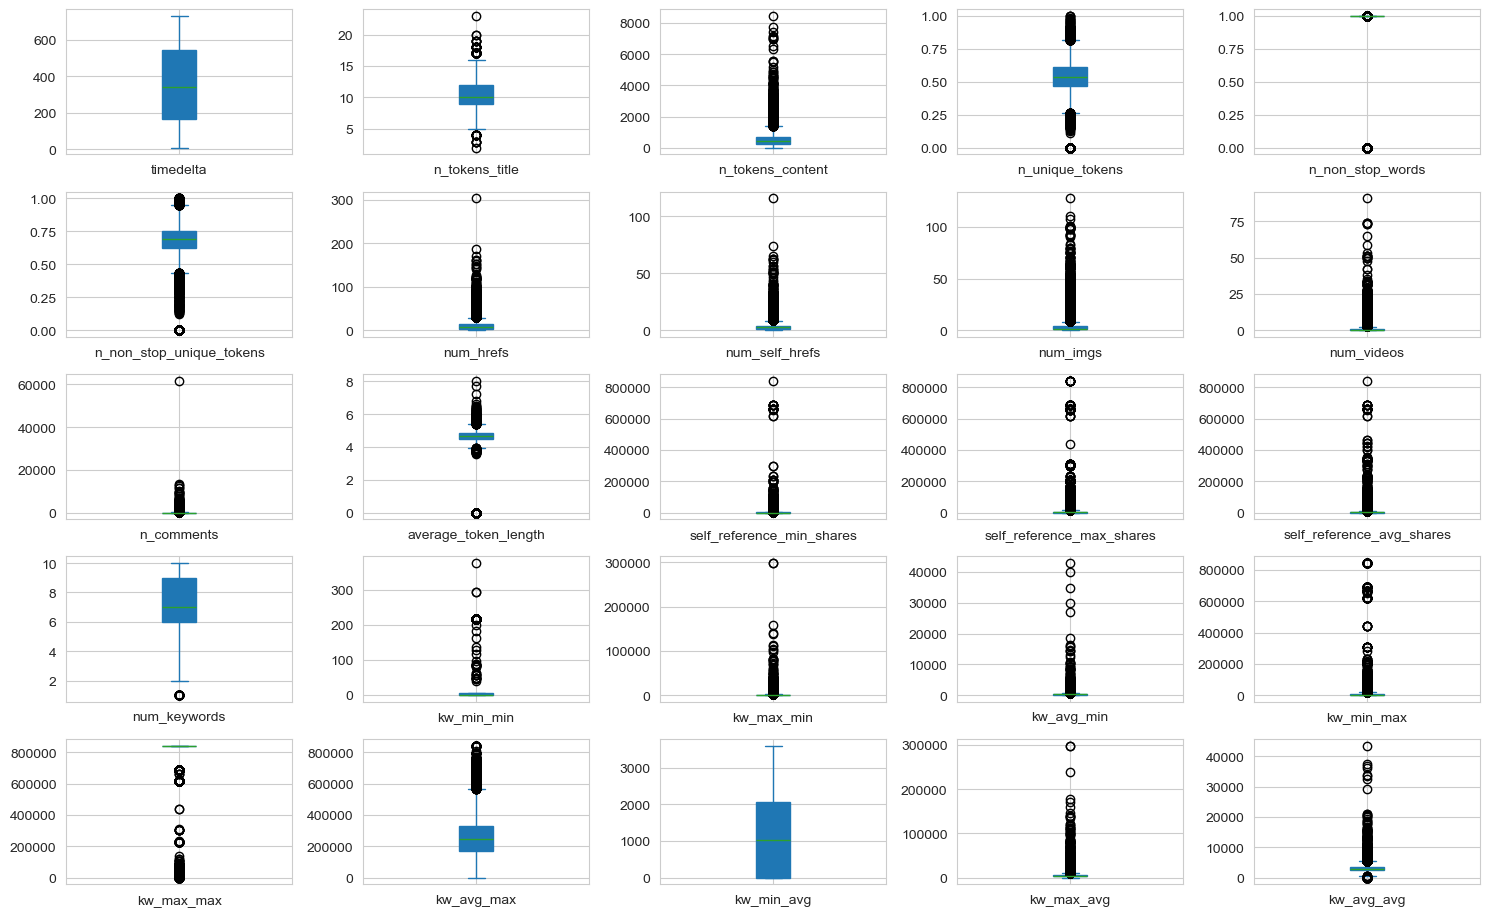

In [6]:
# Outlier Analysis

# Outliers are present in many numerical features, as indicated by the box plots and histograms
# Many numerical features are highly skewed, which may require transformations or scaling for modeling.


# Detect Outliers
# Univariate outlier detection with box plots and histograms

sns.set_style("whitegrid")

# Automatically select numeric columns
num_cols = df.select_dtypes(include=["number"]).columns

# Optional: remove target column
num_cols = num_cols.drop(["shares", "log_shares"], errors="ignore")


# Histograms
df[num_cols].hist(figsize=(15, 20), bins=20, layout=(len(num_cols) // 3 + 3,5))
plt.tight_layout()
plt.show()

# Box plots
df[num_cols].plot(figsize=(15, 20),kind='box', subplots=True, layout=(len(num_cols) // 3 + 3, 5),  patch_artist=True)
plt.tight_layout()
plt.show()




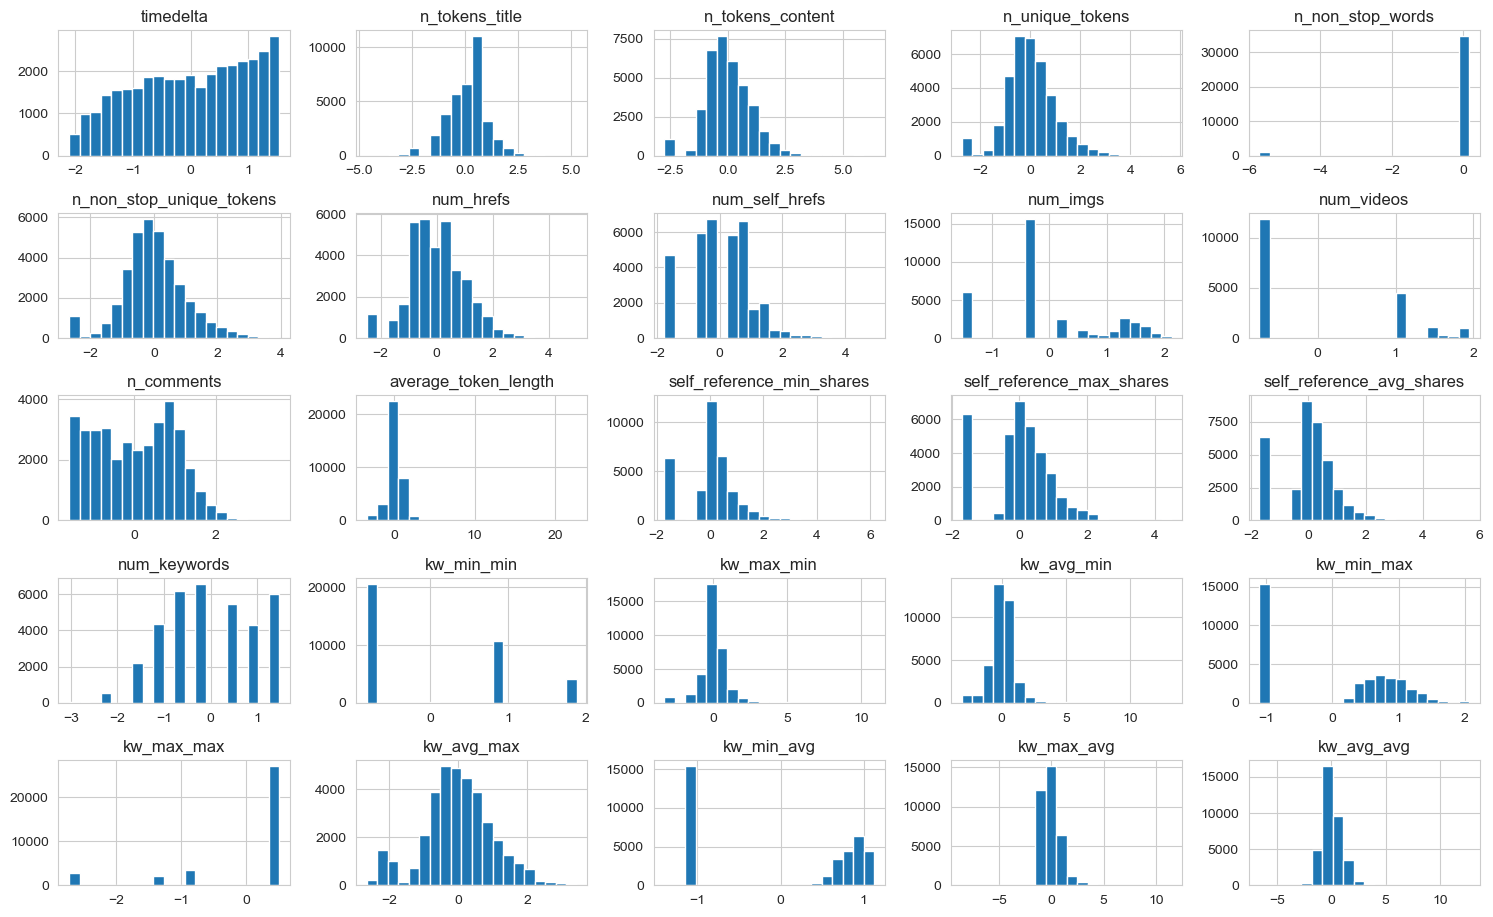

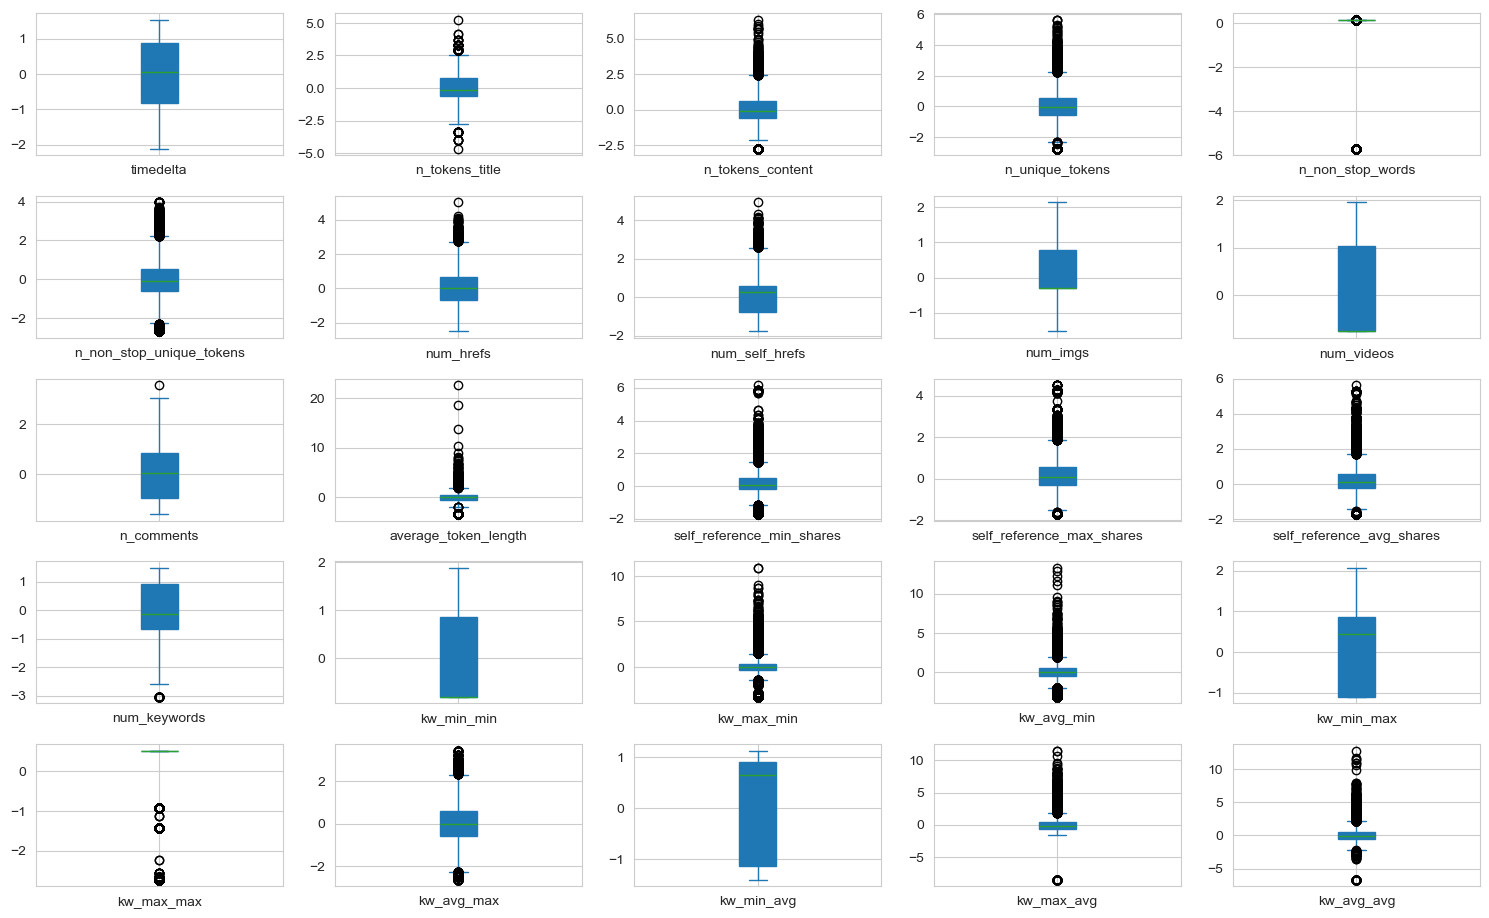

In [7]:
# Outlier Handling - Yeo-Johnson Transformation

# Yeo-Johnson transformation is a power transformation that can handle both positive and negative values
# suitable for features with skewed distributions. 
# It helps stabilize variance and make the data more normally distributed, 
# which can improve the performance of machine learning models.

from sklearn.preprocessing import PowerTransformer

# Select numeric columns
num_cols = df.select_dtypes(include=["number"]).columns

# Optional: remove target column
num_cols = num_cols.drop(["shares", "log_shares"], errors="ignore")

# Apply Yeo-Johnson Transformation
pt = PowerTransformer(method="yeo-johnson")
df[num_cols] = pt.fit_transform(df[num_cols])

# Histograms
df[num_cols].hist(figsize=(15, 20), bins=20, layout=(len(num_cols) // 3 + 3,5))
plt.tight_layout()
plt.show()

# Box plots
df[num_cols].plot(figsize=(15, 20),kind='box', subplots=True, layout=(len(num_cols) // 3 + 3, 5),  patch_artist=True)
plt.tight_layout()
plt.show()

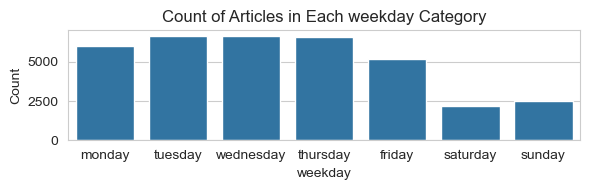

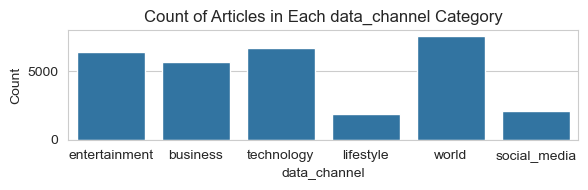

           total_shares  mean_shares  median_shares  article_count
weekday                                                           
monday         21831688  3652.616363         1400.0           5977
tuesday        21403230  3220.467951         1300.0           6646
wednesday      21822980  3275.248387         1300.0           6663
thursday       20847018  3176.446442         1400.0           6563
friday         17057462  3314.059064         1500.0           5147
saturday        9196792  4157.681736         2000.0           2212
sunday          9226151  3732.261731         1900.0           2472


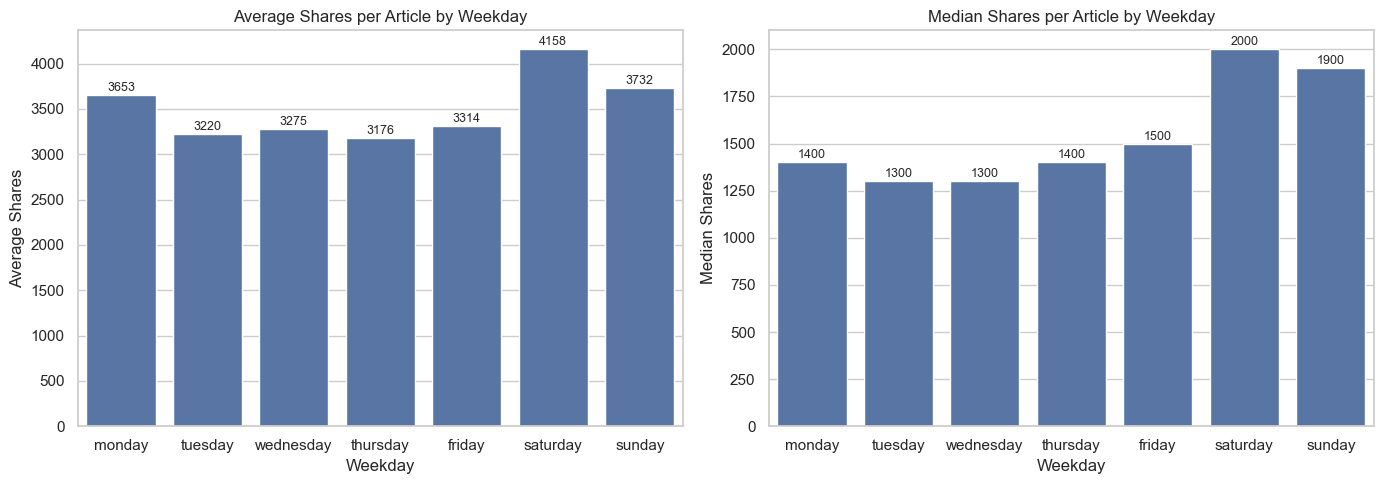

In [8]:
# Categorical Columns

# categorical columns: weekday, data_channel

# Weekend Effect
# Saturday has the highest shares (~4158). Sunday is also relatively high
# Users are more active on weekends


# Histograms for categorical columns
sns.set_style("whitegrid")

# Select categorical columns
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()


for col in cat_cols:
    plt.figure(figsize=(6, 2))
    sns.countplot(x=col, data=df, legend=False)
    plt.title(f'Count of Articles in Each {col} Category')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()



# Ensure weekday order
weekday_order = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']

# Aggregate statistics
weekday_stats = df.groupby('weekday')['shares'].agg(
    total_shares='sum',
    mean_shares='mean',
    median_shares='median',
    article_count='count'
).reindex(weekday_order)

print(weekday_stats)

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Mean Shares per Weekday
sns.barplot(x=weekday_stats.index, y=weekday_stats['mean_shares'], ax=axes[0])
axes[0].set_title('Average Shares per Article by Weekday')
axes[0].set_xlabel('Weekday')
axes[0].set_ylabel('Average Shares')


# Annotate values
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.0f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

# Plot Median Shares per Weekday
sns.barplot(x=weekday_stats.index, y=weekday_stats['median_shares'], ax=axes[1])
axes[1].set_title('Median Shares per Article by Weekday')
axes[1].set_xlabel('Weekday')
axes[1].set_ylabel('Median Shares')


# Annotate values
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.0f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


In [9]:
# DATA CLEANING
import re
import pandas as pd  
import seaborn as sns
import matplotlib.pyplot as plt  
import numpy as np

# Load the dataset  
df = pd.read_csv('./data/mini_project_1_data.csv')    

# Correcting Structural Errors

# Drop identifier / non-predictive columns
# ID: arbitrary row identifier, no predictive value
# URL: high-cardinality text, not used directly
df = df.drop(columns=["ID", "URL"])

# Handle missing values
# data_channel: missing means the article was not tagged with a channel
# treat as its own category "unknown" rather than dropping ~15% of rows

df["data_channel"] = df["data_channel"].fillna("unknown")

# num_videos: ~47% missing. 
# a missing video count almost always means "no video embedded" (videos are optional media), 
# so we impute with 0 rather than the mean, which would understate articles that truly have no video.
df["num_videos"] = df["num_videos"].fillna(0)

# num_hrefs, num_self_hrefs, num_imgs, self_reference_*
# a small fraction (~2%) missing -> impute with the median (robust to the heavy right-skew of these count variables)
median_impute_cols = [
    "num_hrefs", "num_self_hrefs", "num_imgs",
    "self_reference_min_shares", "self_reference_max_shares",
    "self_reference_avg_shares"
]
for col in median_impute_cols:
    df[col] = df[col].fillna(df[col].median())


print(f"\nRemaining missing values after cleaning: {df.isnull().sum().sum()}")




Remaining missing values after cleaning: 0


In [12]:
# FEATURE ENGINEERING

# The features below reflect metrics that online media / digital publishing
# teams (e.g. content strategists, SEO & social media editors) commonly
# track when optimising articles for social sharing:
#
#   (a) Headline optimisation      - ideal title length for click-through
#   (b) Content depth / length     - long-form vs snackable content
#   (c) Visual richness            - images & video per unit of content
#   (d) Internal linking (SEO)     - self-referential links as a % of links
#   (e) Keyword performance        - spread/quality of targeted keywords
#   (f) "Evergreen" content signal - how the referenced articles perform
#   (g) Publish-day effects        - weekday vs weekend posting behaviour
#   (h) Reader engagement proxy    - comment density
#   (i) Content "freshness"        - age of the article at data collection

# (a) Headline length -- industry rule of thumb: titles of ~6-12 words
#     tend to perform best on social feeds; flag short/long/optimal
df["title_length_band"] = pd.cut(
    df["n_tokens_title"], bins=[0, 6, 12, np.inf],
    labels=["short", "optimal", "long"]
)

# (b) Content depth: total content length already exists (n_tokens_content);
#     add a readability-adjacent measure (avg words per "idea" proxied by
#     the ratio of unique tokens to total content length -> lexical density)
df["lexical_density"] = df["n_unique_tokens"] * df["n_non_stop_words"]

# (c) Visual richness: images/videos per 1000 words of content - editors use
#     this to gauge how "scannable"/shareable an article is on social feeds
df["content_length_safe"] = df["n_tokens_content"].replace(0, np.nan)
df["imgs_per_1k_words"] = (df["num_imgs"] / df["content_length_safe"] * 1000).fillna(0)
df["videos_per_1k_words"] = (df["num_videos"] / df["content_length_safe"] * 1000).fillna(0)
df["media_richness"] = df["imgs_per_1k_words"] + df["videos_per_1k_words"]

# (d) Internal linking ratio (SEO / on-site engagement metric): 
#     what fraction of an article's links point back to the same site
df["self_href_ratio"] = np.where(df["num_hrefs"] > 0, df["num_self_hrefs"] / df["num_hrefs"], 0)

# (e) Keyword performance spread: gap between the best- and worst-performing
#     keyword's average shares - large gap suggests reliance on a single
#     "hit" keyword; publishers use this to judge keyword-strategy risk
df["keyword_spread_avg"] = df["kw_max_avg"] - df["kw_min_avg"]
df["keyword_quality_score"] = df["kw_avg_avg"]  # already an average-of-median metric

# (f) Evergreen / network-effect signal: how well articles this article
#     links to have historically performed - a strong predictor since
#     articles referencing popular content tend to inherit some traffic
df["self_reference_range"] = (df["self_reference_max_shares"] - df["self_reference_min_shares"])

# (g) Publish-day effects: weekend posts often see different sharing
#     behaviour (more leisure browsing) than weekday posts
df["is_weekend"] = df["weekday"].isin(["saturday", "sunday"]).astype(int)

# (h) Reader engagement proxy: comments per 1000 words (engagement density
#     rather than raw comment count, which is length-biased)
df["comments_per_1k_words"] = (df["n_comments"] / df["content_length_safe"] * 1000).fillna(0)

# (i) Content freshness bucket: very recent vs older articles at time of
#     collection - proxies algorithmic/organic discovery decay
df["freshness_band"] = pd.cut(df["timedelta"], bins=[-1, 90, 365, np.inf], labels=["recent", "moderate", "old"])

# drop helper column no longer needed
df = df.drop(columns=["content_length_safe"])

print(f"\nFeature engineering complete. Total columns now: {df.shape[1]}")
print(df.info())


Feature engineering complete. Total columns now: 40
<class 'pandas.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 40 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   timedelta                  35680 non-null  float64 
 1   weekday                    35680 non-null  str     
 2   shares                     35680 non-null  int64   
 3   n_tokens_title             35680 non-null  float64 
 4   n_tokens_content           35680 non-null  float64 
 5   n_unique_tokens            35680 non-null  float64 
 6   n_non_stop_words           35680 non-null  float64 
 7   n_non_stop_unique_tokens   35680 non-null  float64 
 8   num_hrefs                  35680 non-null  float64 
 9   num_self_hrefs             35680 non-null  float64 
 10  num_imgs                   35680 non-null  float64 
 11  num_videos                 35680 non-null  float64 
 12  n_comments                 35680 non-null  flo

In [ ]:
# DATA SPLITTING (Train, Validate, Test)

# Split then Scale and Encode
# Split dataset BEFORE applying any transformations
# This prevents data leakage

from sklearn.model_selection import train_test_split

# We model log1p(shares) as the regression target. This is standard practice
# for heavily right-skewed count/virality metrics: it stabilises variance,
# reduces the influence of extreme viral outliers, and makes squared-error
# loss meaningful. Predictions are exponentiated back (expm1) for reporting
# metrics on the original `shares` scale.

X = df.drop(columns=["shares"])
y_raw = df["shares"]
y = np.log1p(y_raw) # log transform target


# Split the data into training (80%) and validation-test (20%) sets
X_train, X_temp, y_train, y_temp, y_raw_train, y_raw_temp = train_test_split(X, y, y_raw, test_size=0.2, random_state=42)

# Split the validation-test set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test, y_raw_val, y_raw_test = train_test_split(X_temp, y_temp, y_raw_temp, test_size=0.5, random_state=42)

print(f"\nTrain size: {X_train.shape[0]}, Validation size: {X_val.shape[0]}, Test size: {X_test.shape[0]}")



Train size: 28544, Validation size: 3568, Test size: 3568


In [ ]:
# PREPROCESSING PIPELINES

# Scaling and Encoding

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, RobustScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder


# Numerical features (continuous variables)
numerical_features = X_train.select_dtypes(include=["number"]).columns

# Nominal categorical features (no order) 
nominal_features = ["weekday", "data_channel", "title_length_band", "freshness_band"]

# Ordinal categorical features (ordered categories)
# ordinal_features = ["title_length_band", "freshness_band"]  
# ordinal_categories = [
#     ["short", "optimal", "long"],  # title_length_band
#     ["recent", "moderate", "old"]  # freshness_band
# ]


# Numerical Transformer - for numerical features
# median-impute (safety net)
# Optional (to test): Power transform (Yeo-Johnson) to handle skewness and outliers
# standardise (needed for the linear/regularised models; harmless for tree ensembles).

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
   # ("power_transform", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

# Nominal Transformer - for categorical variables with no order
# most_frequent-impute (safety net)
# One-hot encoding

nominal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Impute missing values with the most frequent category
    ('onehot', OneHotEncoder(handle_unknown='ignore'))  # Prevents errors on unseen categories
])

# Ordinal Transformer - for categorical features with order
# most_frequent-impute (safety net)
# Ordinal encoding

# ordinal_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent')),  # Impute missing values with the most frequent category
#     ('ordinal', OrdinalEncoder(categories=ordinal_categories))
# ])

# Tree-based models (like Decision Trees, Random Forests, Gradient Boosting) do not require feature scaling.
# Therefore, we can create a separate transformer for tree-based models that skips the scaling step.
# median-impute (safety net)
# Power transform (Yeo-Johnson) to handle skewness and outliers

# tree_numerical_transformer = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     #("power_transform", PowerTransformer(method="yeo-johnson")), # handles skewness and outliers
# ])


# Combine all transformers into a single preprocessor using ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("nom", nominal_transformer, nominal_features),
    # ("ord", ordinal_transformer, ordinal_features)
])


# tree_preprocessor = ColumnTransformer(transformers=[
#     ('num', tree_numerical_transformer, numerical_features),
#     ('nom', nominal_transformer, nominal_features),
#     ('ord', ordinal_transformer, ordinal_features)
# ])




In [14]:
# MODEL DEVELOPMENT

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from xgboost import XGBRegressor



# Linear Regression
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),    
    ('model', LinearRegression())
])

# Ridge Regression L2 Regularization
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=10))
])

# Lasso Regression L1 Regularization
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=0.001, max_iter=5000))
])


# Random Forest Regressor
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        max_depth=10, 
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Gradient Boosting Regressor
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=150, 
        max_depth=3, 
        learning_rate=0.08,
        random_state=42
    ))
])

# XGBoost Regressor
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        n_estimators=500,
        learning_rate=0.1,
        max_depth=8,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42,
        n_jobs=-1
    ))
])



In [26]:
# MODEL EVALUATION
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# The target variable (shares) was log-transformed using log1p to reduce skewness.
# During evaluation, predictions were transformed back to the original scale using expm1, and performance metrics (RMSE, MAE, R²) were computed on the original scale to ensure interpretability.



def evaluate_model(model, X_train, X_val, y_train, y_val, name="Model"):
    """
    Evaluate regression model trained on log-transformed target.
    Metrics are computed on ORIGINAL scale.
    """

    # =========================
    # 1. Train
    # =========================
    model.fit(X_train, y_train)

    # =========================
    # 2. Predict (log scale)
    # =========================
    y_pred_log = model.predict(X_val)

    # =========================
    # 3. Convert back to original scale
    # =========================
    y_pred = np.expm1(y_pred_log)
    y_true = np.expm1(y_val)

    # =========================
    # 4. Metrics (original scale and log scale)
    # =========================
    # # Metrics computed on the ORIGINAL share scale (business-interpretable)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    # Metrics on the LOG scale (model-fit interpretable, less outlier-driven)
    r2_log = r2_score(y_val, y_pred_log)
    mae_log = mean_absolute_error(y_val, y_pred_log)

    print(f"=== Validation Metrics: {name} ===")
    print(f"MAE:  {mae:.5f}")
    print(f"RMSE: {rmse:.5f}")
    print(f"R²:   {r2:.5f}")
    print(f"R² (log-shares): {r2_log:.5f}")
    print(f"MAE (log-shares): {mae_log:.5f}")
    print("\n")

    # =========================
    # 5. Actual vs Predicted
    # =========================
    # plt.figure()
    # sns.scatterplot(x=y_true, y=y_pred, alpha=0.5, hue=y_pred, palette='coolwarm')
    # plt.xlabel("Actual Shares")
    # plt.ylabel("Predicted Shares")
    # plt.title(f"{name}: Actual vs Predicted")
    # plt.show()

    # # =========================
    # # 6. Residual Plot
    # # =========================
    # residuals = y_true - y_pred

    # plt.figure()
    # sns.scatterplot(x=y_pred, y=residuals, alpha=0.5, hue=residuals, palette='coolwarm')
    # plt.axhline(y=0)
    # plt.xlabel("Predicted Shares")
    # plt.ylabel("Residuals")
    # plt.title(f"{name}: Residual Plot")
    # plt.show()

    # =========================
    # 7. Return metrics
    # =========================
    
    return ({
        "Model": name,
        "MAE (shares)": round(mae, 1),
        "RMSE (shares)": round(rmse, 1),
        "R2 (shares)": round(r2, 4),
        "MAE (log-shares)": round(mae_log, 4),
        "R2 (log-shares)": round(r2_log, 4),
    
    })

results = []  # Initialize results list to store evaluation metrics for each model  

results.append(evaluate_model(lr_pipeline, X_train, X_val, y_train, y_val, name="Linear Regression"))
results.append(evaluate_model(ridge_pipeline, X_train, X_val, y_train, y_val, name="Ridge Regression"))
results.append(evaluate_model(lasso_pipeline, X_train, X_val, y_train, y_val, name="Lasso Regression"))
results.append(evaluate_model(rf_pipeline, X_train, X_val, y_train, y_val, name="Random Forest"))
results.append(evaluate_model(gb_pipeline, X_train, X_val, y_train, y_val, name="Gradient Boosting"))
results.append(evaluate_model(xgb_pipeline, X_train, X_val, y_train, y_val, name="XGBoost"))

results_df = pd.DataFrame(results).sort_values("R2 (log-shares)", ascending=False)
print("\n=== MODEL COMPARISON ===")
print(results_df.to_string(index=False))
results_df.to_csv("./output/model_comparison.csv", index=False)


=== Validation Metrics: Linear Regression ===
MAE:  2169.50360
RMSE: 7425.83472
R²:   0.08283
R² (log-shares): 0.20994
MAE (log-shares): 0.62263


=== Validation Metrics: Ridge Regression ===
MAE:  2169.69974
RMSE: 7426.47635
R²:   0.08267
R² (log-shares): 0.20993
MAE (log-shares): 0.62265


=== Validation Metrics: Lasso Regression ===
MAE:  2179.65547
RMSE: 7482.40839
R²:   0.06880
R² (log-shares): 0.20907
MAE (log-shares): 0.62311


=== Validation Metrics: Random Forest ===
MAE:  1805.56725
RMSE: 6567.21224
R²:   0.28266
R² (log-shares): 0.42484
MAE (log-shares): 0.50828


=== Validation Metrics: Gradient Boosting ===
MAE:  1785.67115
RMSE: 6625.45239
R²:   0.26988
R² (log-shares): 0.41892
MAE (log-shares): 0.50692


=== Validation Metrics: XGBoost ===
MAE:  1866.33909
RMSE: 6730.75828
R²:   0.24649
R² (log-shares): 0.41539
MAE (log-shares): 0.51253



=== MODEL COMPARISON ===
            Model  MAE (shares)  RMSE (shares)  R2 (shares)  MAE (log-shares)  R2 (log-shares)
    Random Fo

In [16]:
# Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Linear regression models (Ridge, Lasso) perform much worse than tree-based models.
# we will instead focus on tuning hyperparameters of tree-based models
# we will perform RandomizedSearchCV for efficiency.

# Hyperparameter grids for different models
rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

gbr_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [3, 5, 7],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 3],
}

xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [3, 5, 7],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__gamma": [0, 0.1, 0.3],
    "model__reg_alpha": [0, 0.1],
    "model__reg_lambda": [1, 1.5]
}

# reg_param_grid = {
#     'model__alpha': [0.001,0.01,1000,10000],
#     'model__fit_intercept': [True, False]
# }




In [18]:
# Randomized Search CV
# Perform randomized search with cross-validation for Random Forest
rf_random_search = RandomizedSearchCV(rf_pipeline, rf_param_grid, n_iter=10, cv=3, scoring='r2', n_jobs=-1)
rf_random_search.fit(X_train, y_train)
print(f"Best Random Forest parameters: {rf_random_search.best_params_}")


Best Random Forest parameters: {'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30}


In [19]:
# Perform randomized search with cross-validation for Gradient Boosting
gbr_random_search = RandomizedSearchCV(gb_pipeline, gbr_param_grid, n_iter=10, cv=3, scoring='r2', n_jobs=-1)
gbr_random_search.fit(X_train, y_train)
print(f"Best Gradient Boosting parameters: {gbr_random_search.best_params_}")


Best Gradient Boosting parameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 3, 'model__max_depth': 7, 'model__learning_rate': 0.05}


In [20]:
# Perform randomized search with cross-validation for XGBoost
xgb_random_search = RandomizedSearchCV(xgb_pipeline, xgb_param_grid, n_iter=10, cv=3, scoring='r2', n_jobs=-1)
xgb_random_search.fit(X_train, y_train)
print(f"Best XGBoost parameters: {xgb_random_search.best_params_}")


Best XGBoost parameters: {'model__subsample': 1.0, 'model__reg_lambda': 1.5, 'model__reg_alpha': 0, 'model__n_estimators': 100, 'model__max_depth': 7, 'model__learning_rate': 0.05, 'model__gamma': 0, 'model__colsample_bytree': 0.8}


In [23]:
results = {
    "Random Forest": rf_random_search,
    "Gradient Boosting": gbr_random_search,
    "XGBoost": xgb_random_search
}
    
summary = []

for name, search in results.items():
    summary.append({
        "Model": name,
        "CV R2": search.best_score_
    })

results_df = pd.DataFrame(summary).sort_values(by="CV R2", ascending=False)
print(results_df,"\n")


best_model_name = max(results, key=lambda name: results[name].best_score_)
best_search = results[best_model_name]

print("Best model:", best_model_name)
print("Best CV R2(log-shares):", best_search.best_score_)


               Model     CV R2
1  Gradient Boosting  0.458889
2            XGBoost  0.454891
0      Random Forest  0.421483 

Best model: Gradient Boosting
Best CV R2(log-shares): 0.45888872881207227


In [27]:
# Evaluate the best tuned model after Randomized Search CV on Final Test Set

best_model = best_search.best_estimator_

results.append(evaluate_model(best_model, X_train, X_test, y_train, y_test, name=f"Best Model ({best_model_name}) on Test Set"))

results_df = pd.DataFrame(results).sort_values("R2 (log-shares)", ascending=False)
print("\n=== MODEL COMPARISON ===")
print(results_df.to_string(index=False))
results_df.to_csv("./output/model_comparison.csv", index=False)

=== Validation Metrics: Best Model (Gradient Boosting) on Test Set ===
MAE:  1736.84530
RMSE: 6500.05196
R²:   0.33555
R² (log-shares): 0.45810
MAE (log-shares): 0.47578



=== MODEL COMPARISON ===
                                     Model  MAE (shares)  RMSE (shares)  R2 (shares)  MAE (log-shares)  R2 (log-shares)
Best Model (Gradient Boosting) on Test Set        1736.8         6500.1       0.3355            0.4758           0.4581
                             Random Forest        1805.6         6567.2       0.2827            0.5083           0.4248
                         Gradient Boosting        1785.7         6625.5       0.2699            0.5069           0.4189
                                   XGBoost        1866.3         6730.8       0.2465            0.5125           0.4154
                         Linear Regression        2169.5         7425.8       0.0828            0.6226           0.2099
                          Ridge Regression        2169.7         7426.5       0.08